## 1. Business Understanding
** To predict whether the insuer is coming with attroney or not**


## 2. Data Collection

In [1]:
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

import warnings
warnings.filterwarnings(action="ignore")


In [2]:
cliamants_data = pd.read_csv("cliamants.csv")
cliamants_data

,CASENUM,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,5,0,0.0,1.0,0.0,50.0,34.940
1,3,1,1.0,0.0,0.0,18.0,0.891
2,66,1,0.0,1.0,0.0,5.0,0.330
3,70,0,0.0,1.0,1.0,31.0,0.037
4,96,1,0.0,1.0,0.0,30.0,0.038
...,...,...,...,...,...,...,...
1335,34100,1,0.0,1.0,0.0,NaN,0.576
1336,34110,0,1.0,1.0,0.0,46.0,3.705
1337,34113,1,1.0,1.0,0.0,39.0,0.099
1338,34145,0,1.0,0.0,0.0,8.0,3.177


## 3. Data Understanding

## the dataset has below features

Inputs:
--------

1. case num
2. cliamant sex (clmsex)
3. cliamant insurance(clminsur)
4. seatbelt
5. cliamant age (clmage)
6. loss

Outputs:
________
Attorney

In [3]:
cliamants_data.shape # it has 1340 observation and 7 features

(1340, 7)

In [4]:
cliamants_data.describe()

,CASENUM,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
count,1340.000000,1340.000000,1328.000000,1299.000000,1292.000000,1151.000000,1340.000000
mean,11202.001493,0.488806,0.558735,0.907621,0.017028,28.414422,3.806307
std,9512.750796,0.500061,0.496725,0.289671,0.129425,20.304451,10.636903
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4177.000000,0.000000,0.000000,1.000000,0.000000,9.000000,0.400000
50%,8756.500000,0.000000,1.000000,1.000000,0.000000,30.000000,1.069500
75%,15702.500000,1.000000,1.000000,1.000000,0.000000,43.000000,3.781500
max,34153.000000,1.000000,1.000000,1.000000,1.000000,95.000000,173.604000


In [5]:
cliamants_data.dtypes

CASENUM       int64
ATTORNEY      int64
CLMSEX      float64
CLMINSUR    float64
SEATBELT    float64
CLMAGE      float64
LOSS        float64
dtype: object

In [6]:
cliamants_data.isnull().sum()

CASENUM       0
ATTORNEY      0
CLMSEX       12
CLMINSUR     41
SEATBELT     48
CLMAGE      189
LOSS          0
dtype: int64

## 4. Data preparation

## 4.1 Data cleaning - Because this dataset has null values 

In [7]:
## dropping the null values - as for now we are droping , but in project we need to ask the client and decide

cliamants_data.dropna(axis = 0, inplace = True)
cliamants_data

,CASENUM,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,5,0,0.0,1.0,0.0,50.0,34.940
1,3,1,1.0,0.0,0.0,18.0,0.891
2,66,1,0.0,1.0,0.0,5.0,0.330
3,70,0,0.0,1.0,1.0,31.0,0.037
4,96,1,0.0,1.0,0.0,30.0,0.038
...,...,...,...,...,...,...,...
1334,34104,1,1.0,1.0,0.0,16.0,0.060
1336,34110,0,1.0,1.0,0.0,46.0,3.705
1337,34113,1,1.0,1.0,0.0,39.0,0.099
1338,34145,0,1.0,0.0,0.0,8.0,3.177


In [8]:
1340 - 1096 


244

## 244 record we are droping - this decision need to be discussed with the client before we go for next step

## 4.2 Seperating X and Y values

In [9]:
X = cliamants_data.drop(labels = ["CASENUM","ATTORNEY"],axis = 1)
X

,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,0.0,1.0,0.0,50.0,34.940
1,1.0,0.0,0.0,18.0,0.891
2,0.0,1.0,0.0,5.0,0.330
3,0.0,1.0,1.0,31.0,0.037
4,0.0,1.0,0.0,30.0,0.038
...,...,...,...,...,...
1334,1.0,1.0,0.0,16.0,0.060
1336,1.0,1.0,0.0,46.0,3.705
1337,1.0,1.0,0.0,39.0,0.099
1338,1.0,0.0,0.0,8.0,3.177


In [10]:
y = cliamants_data["ATTORNEY"]
y

0       0
1       1
2       1
3       0
4       1
       ..
1334    1
1336    0
1337    1
1338    0
1339    1
Name: ATTORNEY, Length: 1096, dtype: int64

## 5. Model Building

In [11]:
## Spliting the data 

X_train, X_test, y_train, y_test = train_test_split(X,y,train_size=0.20,shuffle=True,random_state=34)  # split as  80% train data and 20% test data

## ( X_train,y_train)  -- training data
## ( X_test,y_test)    -- testing data(unseen data we splitted from original dataset)

In [12]:
X_train

,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
293,1.0,1.0,0.0,10.0,3.330
652,1.0,1.0,0.0,0.0,0.116
424,0.0,0.0,0.0,15.0,0.540
1220,1.0,1.0,0.0,47.0,0.600
1338,1.0,0.0,0.0,8.0,3.177
...,...,...,...,...,...
731,0.0,1.0,0.0,30.0,4.014
817,0.0,1.0,0.0,48.0,0.390
557,0.0,1.0,0.0,30.0,0.565
386,1.0,1.0,0.0,35.0,0.860


In [13]:
logistic_model = LogisticRegression() # call the model

## 6. Model Training

In [14]:
logistic_model.fit(X_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


## 7. Model Testing

## 7.1 Training data

In [15]:
y_pred_train = logistic_model.predict(X_train)
y_pred_train

array([0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0,
       1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0,
       0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0,
       1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0,
       0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1,
       0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1,
       1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0,
       0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0])

## 7.2 Testing data

In [16]:
y_pred_test = logistic_model.predict(X_test)
y_pred_test

array([0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1,
       1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0,
       0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1,
       1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1,
       0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1,
       0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0,
       0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1,
       0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1,
       1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1,
       1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0,
       0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0,
       0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 0,
       0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1,
       1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1,

In [30]:
#cliamants_data["predicted_output"] = logistic_model.predict(X) 
#cliamants_data

,CASENUM,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS,predicted_output
0,5,0,0.0,1.0,0.0,50.0,34.940,0
1,3,1,1.0,0.0,0.0,18.0,0.891,1
2,66,1,0.0,1.0,0.0,5.0,0.330,1
3,70,0,0.0,1.0,1.0,31.0,0.037,0
4,96,1,0.0,1.0,0.0,30.0,0.038,1
...,...,...,...,...,...,...,...,...
1334,34104,1,1.0,1.0,0.0,16.0,0.060,1
1336,34110,0,1.0,1.0,0.0,46.0,3.705,0
1337,34113,1,1.0,1.0,0.0,39.0,0.099,1
1338,34145,0,1.0,0.0,0.0,8.0,3.177,0


## In above we can see that the attorney(actual output) and the predicted_output(predict output by logistic regression) are having same values predictions

	                                      **EVALUATION METRICS IN CLASSIFICATION**
**Metrics**       ---->                                        	**Purpose**

Confusion matrix --->	Inorder to know the misclassification counts done by our model

Precision       ---->	It speaks about individual class STABILITY

Recall          ---->	It speaks about individual class ACCURACY

ROC	            ---->   It speaks about how well my model is gonna behave in real time. It speaks the probability.

AUC	            ---->   It speaks about separability

F1-SCORE	    ---->   It is combination of precision and recall

Accuracy        ---->	Overall accuracy


## 8. Model Evaluation

In [28]:
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix,auc,roc_auc_score,roc_curve

## 8.1 Training Data's Evaluation Metrics

In [24]:
print(confusion_matrix(y_train, y_pred_train))

[[78 42]
 [22 77]]
The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


In [23]:
print(classification_report(y_train, y_pred_train))

              precision    recall  f1-score   support

           0       0.78      0.65      0.71       120
           1       0.65      0.78      0.71        99

    accuracy                           0.71       219
   macro avg       0.71      0.71      0.71       219
weighted avg       0.72      0.71      0.71       219



## ROC - Reciever Operating characteristics

0.7138888888888888


Text(0, 0.5, 'True Positive Rate')

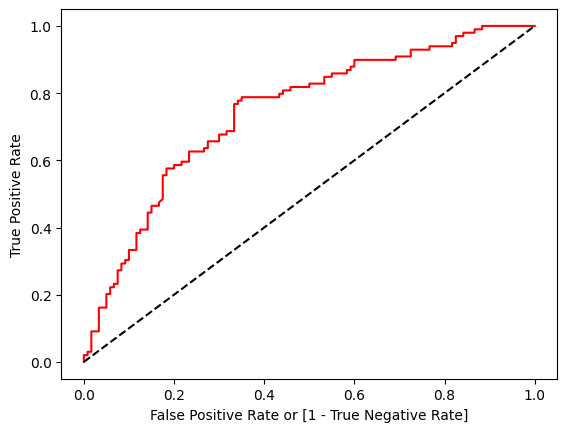

In [30]:
fpr, tpr, thresholds = roc_curve(y_train, logistic_model.predict_proba (X_train)[:,1])

auc = roc_auc_score(y_train,y_pred_train)
print(auc)

import matplotlib.pyplot as plt
plt.plot(fpr, tpr, color='red', label='logit model ( area  = %0.2f)'%auc)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate or [1 - True Negative Rate]')
plt.ylabel('True Positive Rate')

In [18]:
accuracy_score(y_train,y_pred_train)

0.7077625570776256

## 8.2 Test Data's Evaluation Metrics

   Confuison matrix is matrix between ACTUAL OUTPUT and PREDICTED OUTPUT

                               Predicted Output
                              0                       1
                        
                    0   True negative          False positive
   Actual Output                 
 
                    1   False negative         True positive

---> positive relays on the Predicted output 

   = TRUE PREDICTIONS / SUMATION OF ALL PREDICTIONS

   = True Positive + True Negative / (True positive + True Negative + False Positive + False negative)

i.e here 302 - True negative , 156 - False positive , 97 - False Negative , 322 - True positive

 = 322 + 302 /(302+156+97+322)
 = 624 / 877
 = 0.711

**In ACCURACY - UNDER F1-SCORE we will find 0.71**
   

In [27]:
print(confusion_matrix(y_test, y_pred_test))

[[302 156]
 [ 97 322]]


In [26]:
print(classification_report(y_test, y_pred_test))

              precision    recall  f1-score   support

           0       0.76      0.66      0.70       458
           1       0.67      0.77      0.72       419

    accuracy                           0.71       877
   macro avg       0.72      0.71      0.71       877
weighted avg       0.72      0.71      0.71       877



In [19]:
accuracy_score(y_test,y_pred_test)

0.7115165336374002

0.7139425331679711


Text(0, 0.5, 'True Positive Rate')

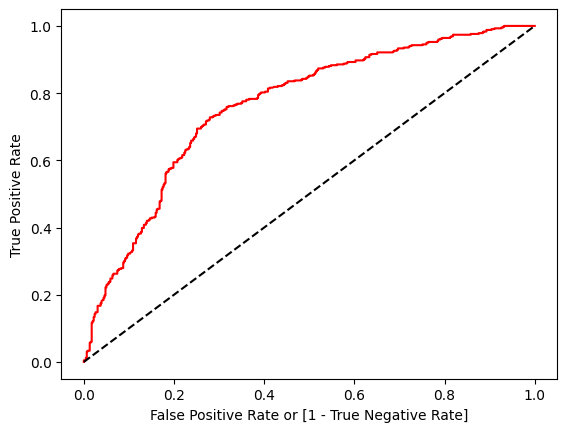

In [34]:
fpr, tpr, thresholds = roc_curve(y_test, logistic_model.predict_proba (X_test)[:,1])

auc = roc_auc_score(y_test,y_pred_test)
print(auc)

import matplotlib.pyplot as plt
plt.plot(fpr, tpr, color='red', label='logit model ( area  = %0.2f)'%auc)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate or [1 - True Negative Rate]')
plt.ylabel('True Positive Rate')

## By checking both the Training and Testing Accuracy we can see 70-71% of accuracy

In [31]:
#accuracy_score(y_true=y, y_pred=y_pred) y-actual output, y_pred-predicted output

0.708029197080292

## The above score shows that we got 70% ACCURACY PREDICTION

## 9. Model Deployment

In [20]:
from pickle import dump

In [34]:
dump(logistic_model,open("cliamants.pkl","wb"))  # will created in the logistic regression folder

## the above pickle file will be used in UI to predict the insurance cliam with attroney or not

                           ****************THE END***************

## 10. CICD - Devops team will deploy the product to business